# 03 Style clusters: Gaussian mixture on the first 5 principal components

Inputs: `features.clustering_matrix(profiles)` (8 **era-relative** z-scores of shrunk style features: each fighter is standardized against
same-division fighters with career midpoints within ±4 years; eligible fighters, full careers),
projected onto the first 5 principal components (85% of the variance; `notebooks/02_pca.ipynb`). Model: Gaussian mixture with full
covariance (`src/clustering.py`). Clusters are numbered by size (cluster 1 = largest) and are **deliberately not named**.
Continuous style axes (`notebooks/05_style_axes.ipynb`) are the main description of fighters; clusters are a secondary shorthand.

The fitted models and per-fighter probabilities are written by `python src/clustering.py`. This notebook refits the same models with the
same seed to analyse them.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F
import clustering as CL

pd.set_option("display.width", 220, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
X = F.clustering_matrix(profiles)
pca = CL.fit_pca(X)
Z = pca.transform(X.values)
info = profiles.set_index("fighter_id").loc[X.index]
print(f"{len(X):,} eligible fighters; {CL.N_COMPONENTS} PCs explain {pca.explained_variance_ratio_.sum():.1%}")
FAMOUS = ["Georges St-Pierre", "Khabib Nurmagomedov", "Jon Jones", "Anderson Silva", "Conor McGregor", "Israel Adesanya",
          "Max Holloway", "Demian Maia", "Charles Oliveira", "Merab Dvalishvili", "Jose Aldo", "Francis Ngannou", "Amanda Nunes",
          "Valentina Shevchenko", "Zhang Weili", "Joanna Jedrzejczyk", "Alexander Volkanovski", "Kamaru Usman", "Nate Diaz",
          "Jailton Almeida", "Sean Strickland", "Demetrious Johnson", "Daniel Cormier", "Stipe Miocic", "Dustin Poirier",
          "Islam Makhachev", "Alex Pereira", "Justin Gaethje", "Chael Sonnen", "Matt Hughes"]

1,240 eligible fighters; 5 PCs explain 84.5%


## 1. Choosing the number of clusters

For each k: **BIC** of the full-data fit (lower is better), and **bootstrap stability**. Refit on 50 resamples of fighters (with
replacement), assign every fighter with the refit model, and compare with the full-data assignment using the adjusted Rand index
(ARI: 1 = identical partition, 0 = chance). The PCA is held fixed during the bootstrap.

The requested range is k = 3–10. k = 1 and 2 are included as reference rows (k = 1 is trivially "stable").

,bic,aic,ari_mean,ari_sd,ari_p10,smallest_cluster,mean_max_prob,in requested range
k,,,,,,,,
1,18533.359,18430.901,1.000,0.000,1.000,1240,1.000,False
2,18233.188,18023.151,0.728,0.090,0.636,482,0.860,False
3,18167.510,17849.892,0.624,0.123,0.439,254,0.794,True
4,18226.645,17801.447,0.531,0.121,0.326,242,0.761,True
5,18314.532,17781.754,0.392,0.101,0.262,163,0.737,True
6,18410.957,17770.599,0.391,0.072,0.304,124,0.700,True
7,18521.163,17773.224,0.336,0.068,0.249,115,0.680,True
8,18619.689,17764.171,0.296,0.053,0.224,55,0.706,True
9,18757.605,17794.506,0.300,0.063,0.217,46,0.709,True


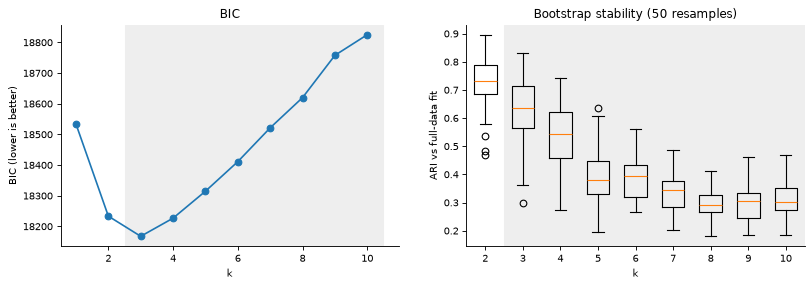

Within k = 3-10: lowest BIC at k = 3, most stable at k = 3.
Recommended k = 3; next-best k = 4.


In [2]:
summary, boot = CL.select_k(Z, ks=range(1, 11), n_boot=50)
show = summary.copy()
show["in requested range"] = show.index >= 3
display(show.round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.plot(summary.index, summary["bic"], marker="o")
a1.set_xlabel("k"); a1.set_ylabel("BIC (lower is better)"); a1.set_title("BIC")
data = [boot.loc[boot["k"] == k, "ari"] for k in range(2, 11)]
a2.boxplot(data, positions=range(2, 11), widths=0.6)
a2.set_xlabel("k"); a2.set_ylabel("ARI vs full-data fit"); a2.set_title("Bootstrap stability (50 resamples)")
for a in (a1, a2):
    a.axvspan(2.5, 10.5, color="#eeeeee", zorder=-1)
plt.show()

rng = summary.loc[3:10]
print(f"Within k = 3-10: lowest BIC at k = {rng['bic'].idxmin()}, most stable at k = {rng['ari_mean'].idxmax()}.")
print(f"Recommended k = {CL.CHOSEN_K}; next-best k = {CL.RUNNER_UP_K}.")

**Recommendation: k = 3, with k = 4 as the next-best option.**

- Within k = 3–10, k = 3 has both the **lowest BIC** and the **highest bootstrap stability** (mean ARI about 0.62). k = 4 is second on both
  (ARI about 0.53). The same ranking held with division-only standardization (ARI 0.70 and 0.49), so **k = 3 still holds** with
  era-relative features. It is slightly less stable, because era differences no longer help separate fighters.
- From k = 5 on, stability falls to about 0.3–0.4. Partitions into 5+ groups mostly don't reproduce on resampled data, so I wouldn't
  interpret them.
- Even k = 3 is only **moderately** stable (ARI 0.8+ is usually called stable). BIC strongly prefers a mixture to a single Gaussian
  (k = 1), so the style space isn't one blob, but the groups overlap heavily. The **membership probabilities** (soft assignments) are more
  informative than the hard labels, especially for fighters between clusters.
- k = 2 has a slightly worse BIC than k = 3 and is more stable. It's outside the requested range and is shown only for context.

## 2. Fit the recommended and next-best models

k = 3: sizes {1: 500, 2: 486, 3: 254}; mean max probability 0.79; share of fighters with max probability < 0.6: 18%
k = 4: sizes {1: 409, 2: 303, 3: 286, 4: 242}; mean max probability 0.76; share of fighters with max probability < 0.6: 23%


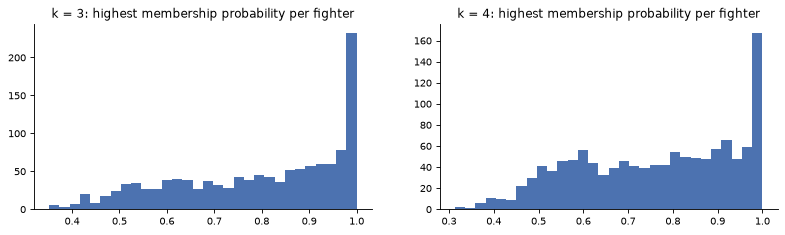

In [3]:
models = {k: CL.fit_style_model(profiles, k) for k in (CL.CHOSEN_K, CL.RUNNER_UP_K)}
assign = {k: m.assign(profiles).set_index("fighter_id").loc[X.index] for k, m in models.items()}
for k, a in assign.items():
    sizes = a["cluster"].value_counts().sort_index()
    print(f"k = {k}: sizes {sizes.to_dict()}; mean max probability {a['max_prob'].mean():.2f}; "
          f"share of fighters with max probability < 0.6: {(a['max_prob'] < 0.6).mean():.0%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, (k, a) in zip(axes, assign.items()):
    ax.hist(a["max_prob"], bins=30, color="#4C72B0")
    ax.set_title(f"k = {k}: highest membership probability per fighter")
plt.show()

## 3. Baseline: k-means at the same k

k-means on the same 5 PC scores. Agreement is the ARI and the share of fighters in matching clusters after optimal label matching.

In [4]:
for k, a in assign.items():
    gmm_labels = a["cluster"].values - 1
    r = CL.kmeans_agreement(Z, gmm_labels, k)
    ct = pd.DataFrame(r["crosstab"], index=[f"GMM {i + 1}" for i in range(k)], columns=[f"k-means {j + 1}" for j in range(k)])
    print(f"k = {k}: ARI = {r['ari']:.2f}; fighters in matched clusters = {r['matched_share']:.0%}")
    display(ct)

k = 3: ARI = 0.34; fighters in matched clusters = 71%


,k-means 1,k-means 2,k-means 3
GMM 1,360,121,19
GMM 2,79,82,325
GMM 3,39,200,15


k = 4: ARI = 0.39; fighters in matched clusters = 71%


,k-means 1,k-means 2,k-means 3,k-means 4
GMM 1,31,46,272,60
GMM 2,0,235,18,50
GMM 3,192,3,71,20
GMM 4,14,29,12,187


## 4. Cluster profiles (k = 3)

Means over fighters hard-assigned to each cluster. **Raw units** are the shrunk features (shares are fractions; rates are per 15 min or
per minute). **Division z-scores** are the within-division standardized values, which are what the clustering saw. Skill measures are
shown for context only; they weren't used to fit the clusters.

In [5]:
RAW = F.STYLE_FEATURES
Zc = [f"z_{f}" for f in F.STYLE_FEATURES]
def profile_tables(k):
    a = assign[k].join(info[RAW + F.SKILL_MEASURES + Zc + ["fight_time_min"]])
    g = a.groupby("cluster")
    raw = g[RAW].mean()
    raw.insert(0, "fighters", g.size())
    allrow = a[RAW].mean().to_frame("all").T
    allrow.insert(0, "fighters", len(a))
    raw = pd.concat([raw, allrow])
    z = g[Zc].mean().set_axis(RAW, axis=1)
    skill = pd.concat([g[F.SKILL_MEASURES + ["fight_time_min"]].mean(), a[F.SKILL_MEASURES + ["fight_time_min"]].mean().to_frame("all").T])
    return raw, z, skill

raw3, z3, skill3 = profile_tables(CL.CHOSEN_K)
print("Raw units (shrunk features):"); display(raw3)
print("Division z-scores:"); display(z3.style.background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, axis=None).format("{:.2f}"))
print("Skill measures (not used in clustering):"); display(skill3)

Raw units (shrunk features):


,fighters,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
1,500,0.858,0.071,0.071,0.783,0.127,0.091,3.141,0.164,0.479,8.507
2,486,0.785,0.093,0.122,0.794,0.127,0.079,5.103,0.269,0.629,7.289
3,254,0.813,0.106,0.081,0.722,0.162,0.117,3.513,0.190,0.436,8.080
all,1240,0.820,0.087,0.093,0.775,0.134,0.091,3.986,0.210,0.529,7.942


Division z-scores:


,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
cluster,,,,,,,,,,
1,0.59,-0.46,-0.46,0.17,-0.25,-0.01,-0.48,-0.55,-0.29,0.33
2,-0.59,0.17,0.65,0.40,-0.21,-0.42,0.63,0.72,0.62,-0.45
3,-0.11,0.60,-0.27,-1.12,0.90,0.86,-0.27,-0.26,-0.56,0.08


Skill measures (not used in clustering):


,str_acc,str_def,td_acc,td_def,kd_per15,str_diff_per_min,fight_time_min
1,0.435,0.554,0.376,0.634,0.463,-0.124,115.156
2,0.461,0.536,0.394,0.621,0.274,-0.015,124.413
3,0.487,0.549,0.379,0.643,0.339,0.460,134.832
all,0.456,0.546,0.384,0.631,0.363,0.038,122.814


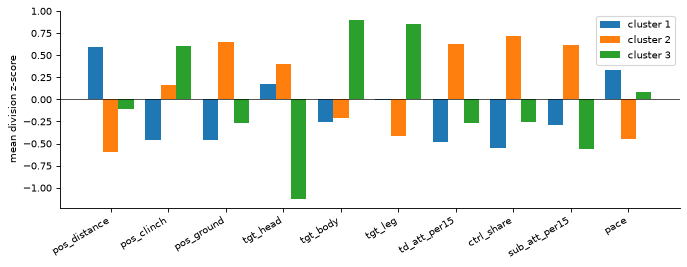

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.2))
w = 0.8 / len(z3)
for i, (c, row) in enumerate(z3.iterrows()):
    ax.bar(np.arange(len(RAW)) + i * w, row.values, width=w, label=f"cluster {c}")
ax.set_xticks(np.arange(len(RAW)) + w * (len(z3) - 1) / 2, RAW, rotation=30, ha="right")
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("mean division z-score")
ax.legend()
plt.show()

### Most representative fighters and well-known mixed members (k = 3)

Top 10 per cluster by membership probability. Then well-known fighters whose highest probability is below 0.8.

In [7]:
def representatives(k, n=10):
    a = assign[k]
    cols = {}
    for c in range(1, k + 1):
        top = a.nlargest(n, f"p_cluster_{c}")
        cols[f"cluster {c}"] = [f"{r.fighter_name} ({getattr(r, f'p_cluster_{c}'):.2f}, {r.division.replace('weight', 'wt')})" for r in top.itertuples()]
    return pd.DataFrame(cols, index=range(1, n + 1))

def mixed(k, threshold=0.8):
    a = assign[k]
    m = a[a["fighter_name"].isin(FAMOUS)]
    pc = [f"p_cluster_{c}" for c in range(1, k + 1)]
    return m.loc[m["max_prob"] < threshold, ["fighter_name", "division", "cluster"] + pc].sort_values("fighter_name").set_index("fighter_name").round(2)

display(representatives(CL.CHOSEN_K))
fam = assign[CL.CHOSEN_K][assign[CL.CHOSEN_K]["fighter_name"].isin(FAMOUS)]
print(f"Well-known fighters: {len(fam)} eligible; {int((fam['max_prob'] < 0.8).sum())} have max probability < 0.8")
display(mixed(CL.CHOSEN_K))
print("All well-known fighters, hard cluster (k = 3):")
display(fam.groupby("cluster")["fighter_name"].apply(lambda s: ", ".join(sorted(s))).to_frame())

,cluster 1,cluster 2,cluster 3
1,"Sean Strickland (1.00, Middlewt)","Charles Oliveira (1.00, Lightwt)","Chris Gutierrez (1.00, Bantamwt)"
2,"Nam Phan (1.00, Featherwt)","Aleksei Oleinik (1.00, Heavywt)","Brandon Vera (1.00, Light Heavywt)"
3,"Nasrat Haqparast (1.00, Lightwt)","Jaqueline Amorim (1.00, Women's Strawwt)","John Lineker (1.00, Bantamwt)"
4,"Eddie Wineland (1.00, Bantamwt)","Jailton Almeida (1.00, Heavywt)","Caol Uno (1.00, Lightwt)"
5,"Sean Spencer (1.00, Welterwt)","TJ Waldburger (1.00, Welterwt)","Rafael Fiziev (1.00, Lightwt)"
6,"Esteban Ribovics (1.00, Lightwt)","Cole Miller (1.00, Featherwt)","Demetrious Johnson (1.00, Flywt)"
7,"Michael Bisping (1.00, Middlewt)","Paul Sass (1.00, Lightwt)","Marcin Prachnio (1.00, Light Heavywt)"
8,"Joshua Van (0.99, Flywt)","Renato Sobral (1.00, Light Heavywt)","Fabio Maldonado (1.00, Light Heavywt)"
9,"Calvin Kattar (0.99, Featherwt)","Jim Miller (1.00, Lightwt)","Paulo Costa (1.00, Middlewt)"
10,"Alex Morono (0.99, Welterwt)","Stefan Struve (1.00, Heavywt)","Michel Pereira (1.00, Middlewt)"


Well-known fighters: 30 eligible; 5 have max probability < 0.8


,division,cluster,p_cluster_1,p_cluster_2,p_cluster_3
fighter_name,,,,,
Alex Pereira,Light Heavyweight,3,0.24,0.00,0.76
Daniel Cormier,Light Heavyweight,2,0.31,0.61,0.08
Francis Ngannou,Heavyweight,1,0.63,0.34,0.03
Georges St-Pierre,Welterweight,2,0.00,0.75,0.25
Jon Jones,Light Heavyweight,3,0.21,0.00,0.79


All well-known fighters, hard cluster (k = 3):


,fighter_name
cluster,
1,"Conor McGregor, Francis Ngannou, Jose Aldo, Ma..."
2,"Amanda Nunes, Chael Sonnen, Charles Oliveira, ..."
3,"Alex Pereira, Alexander Volkanovski, Anderson ..."


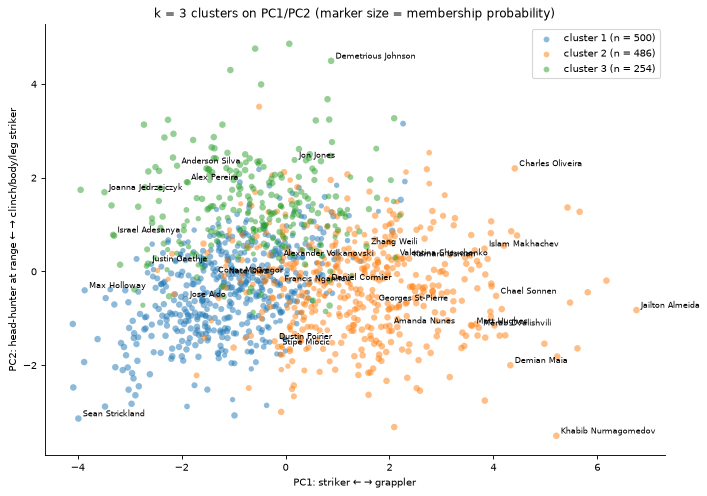

In [8]:
a = assign[CL.CHOSEN_K]
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(1, CL.CHOSEN_K + 1):
    s = a[a["cluster"] == c]
    ax.scatter(s["PC1"], s["PC2"], s=10 + 25 * s["max_prob"], alpha=0.5, lw=0, label=f"cluster {c} (n = {len(s)})")
for r in fam.itertuples():
    ax.annotate(r.fighter_name, (r.PC1, r.PC2), xytext=(4, 2), textcoords="offset points", fontsize=7.5)
ax.set_xlabel("PC1: striker ← → grappler"); ax.set_ylabel("PC2: head-hunter at range ← → clinch/body/leg striker")
ax.set_title("k = 3 clusters on PC1/PC2 (marker size = membership probability)")
ax.legend()
plt.show()

## 5. Confounding checks (k = 3): division and era

The style features are now standardized within division **and** career era (±4-year window around each fighter's career midpoint),
so neither should be strongly associated with the clusters. With division-only standardization, the era association was V = 0.17 at
k = 3. Era = the median year of the fighter's UFC fights since 2000. Cramér's V summarizes
association: 0 = none, 1 = the cluster is fully determined by the variable. Under about 0.1 is usually read as negligible, and about
0.1–0.3 as weak.

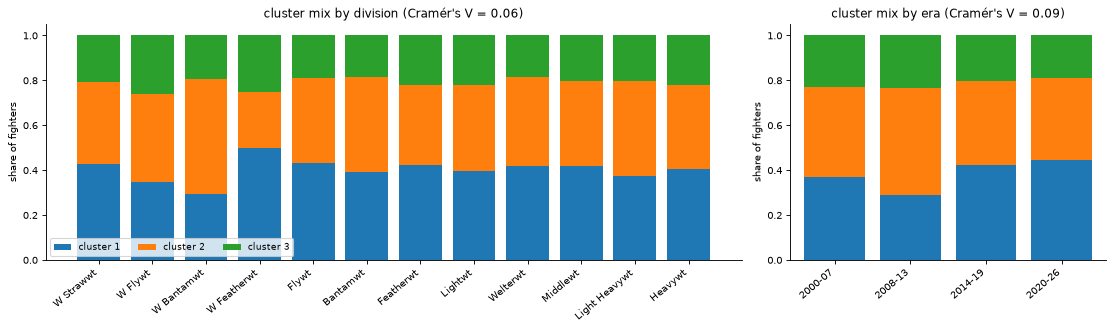

Cluster mix by division, row % (Cramér's V = 0.06):


cluster,fighters,1,2,3
division,,,,
Women's Strawweight,63,43%,37%,21%
Women's Flyweight,46,35%,39%,26%
Women's Bantamweight,41,29%,51%,20%
Women's Featherweight,4,50%,25%,25%
Flyweight,74,43%,38%,19%
Bantamweight,120,39%,42%,18%
Featherweight,128,42%,36%,22%
Lightweight,206,40%,38%,22%
Welterweight,186,42%,40%,18%


Cluster mix by era, row % (Cramér's V = 0.09):


cluster,fighters,1,2,3
event_date,,,,
2000-07,70,37%,40%,23%
2008-13,240,29%,48%,23%
2014-19,415,42%,37%,20%
2020-26,515,44%,37%,19%
all fighters,1240,40%,39%,20%


In [9]:
DIV_ORDER = ["Women's Strawweight", "Women's Flyweight", "Women's Bantamweight", "Women's Featherweight", "Flyweight",
             "Bantamweight", "Featherweight", "Lightweight", "Welterweight", "Middleweight", "Light Heavyweight", "Heavyweight"]
med_year = ff[ff["fighter_id"].isin(X.index)].groupby("fighter_id")["event_date"].apply(lambda s: int(s.str[:4].astype(int).median()))
ERA_BINS, ERA_LABELS = [1999, 2007, 2013, 2019, 2026], ["2000-07", "2008-13", "2014-19", "2020-26"]
era = pd.cut(med_year.reindex(X.index), ERA_BINS, labels=ERA_LABELS)

def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1))

def confound(k):
    a = assign[k]
    out = {}
    for name, var, order in (("division", info["division"], DIV_ORDER), ("era", era, ERA_LABELS)):
        ct = pd.crosstab(var, a["cluster"]).reindex([o for o in order if o in set(var.dropna())])
        share = ct.div(ct.sum(axis=1), axis=0)
        overall = a["cluster"].value_counts(normalize=True).sort_index()
        out[name] = (ct, share, overall, cramers_v(ct))
    return out

def show_confound(k):
    res = confound(k)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
    for ax, (name, (ct, share, overall, v)) in zip(axes, res.items()):
        bottom = np.zeros(len(share))
        for c in share.columns:
            ax.bar(range(len(share)), share[c].values, bottom=bottom, label=f"cluster {c}")
            bottom += share[c].values
        ax.set_xticks(range(len(share)), [s.replace("Women's ", "W ").replace("weight", "wt") for s in share.index], rotation=40, ha="right")
        ax.set_ylabel("share of fighters"); ax.set_title(f"cluster mix by {name} (Cramér's V = {v:.2f})")
    axes[0].legend(ncol=k, fontsize=8, loc="lower left")
    plt.tight_layout(); plt.show()
    for name, (ct, share, overall, v) in res.items():
        t = (share * 100).round(0).astype(int).astype(str) + "%"
        t.insert(0, "fighters", ct.sum(axis=1).astype(str))
        t.loc["all fighters"] = ["%d" % ct.values.sum()] + [f"{x:.0%}" for x in overall.values]
        print(f"Cluster mix by {name}, row % (Cramér's V = {v:.2f}):")
        display(t)
    return res

conf3 = show_confound(CL.CHOSEN_K)

In [10]:
# Feature means by era: era-relative z (what the clusters use) vs division-only z (previous version).
zt = info[Zc].set_axis(RAW, axis=1).groupby(era, observed=True).mean()
zd = info[[f"zdiv_{f}" for f in RAW]].set_axis(RAW, axis=1).groupby(era, observed=True).mean()
print("era-relative z, mean by era:")
display(zt.round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6, axis=None).format("{:.2f}"))
print("division-only z, mean by era (for contrast):")
display(zd.round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6, axis=None).format("{:.2f}"))

# Same clustering pipeline on division-only z-scores, for a before/after comparison of the era association.
Xdiv = profiles[profiles["eligible"] & profiles["std_group"].notna()].set_index("fighter_id")[[f"zdiv_{f}" for f in F.CLUSTER_FEATURES]]
Zdiv = CL.fit_pca(Xdiv).transform(Xdiv.values)
for k in (CL.CHOSEN_K, CL.RUNNER_UP_K):
    lab = CL.fit_gmm(Zdiv, k).predict(Zdiv)
    v_div = cramers_v(pd.crosstab(era.loc[Xdiv.index], lab))
    v_era = cramers_v(pd.crosstab(era, assign[k]["cluster"]))
    print(f"k = {k}: Cramér's V with era: division-only features {v_div:.3f} -> era-relative features {v_era:.3f}")
xt = pd.crosstab(era, assign[CL.CHOSEN_K]["cluster"], normalize="columns").round(2)
print("Era mix within each cluster (column %):"); display(xt)

era-relative z, mean by era:


,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
event_date,,,,,,,,,,
2000-07,-0.11,0.05,0.10,-0.02,0.05,-0.01,-0.05,0.04,-0.03,-0.22
2008-13,-0.11,0.10,0.08,-0.00,-0.02,0.02,0.04,0.06,0.09,-0.04
2014-19,0.00,-0.01,0.01,0.01,-0.02,0.01,-0.03,-0.02,-0.00,-0.03
2020-26,0.03,-0.03,-0.02,-0.01,0.02,0.01,0.01,0.01,-0.01,0.01


division-only z, mean by era (for contrast):


,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
event_date,,,,,,,,,,
2000-07,-0.84,0.65,0.69,0.26,-0.33,-0.06,0.03,0.36,0.52,-0.62
2008-13,-0.49,0.49,0.33,0.15,-0.20,-0.02,0.17,0.23,0.34,-0.31
2014-19,0.06,-0.01,-0.07,0.01,-0.01,-0.01,-0.06,-0.10,-0.12,-0.02
2020-26,0.30,-0.30,-0.19,-0.11,0.15,0.02,-0.04,-0.08,-0.13,0.24


k = 3: Cramér's V with era: division-only features 0.168 -> era-relative features 0.086
k = 4: Cramér's V with era: division-only features 0.153 -> era-relative features 0.066
Era mix within each cluster (column %):


cluster,1,2,3
event_date,,,
2000-07,0.05,0.06,0.06
2008-13,0.14,0.24,0.22
2014-19,0.35,0.32,0.33
2020-26,0.46,0.39,0.39


**Reading the checks (k = 3)**

- **Division: no meaningful association** (Cramér's V about 0.06). Every division's cluster mix is within a few points of the overall mix.
- **Era: the confounding is largely gone.** V fell from 0.17 (division-only features) to about 0.09 at k = 3 (about 0.07 at k = 4),
  below the usual 0.1 threshold for negligible. The era-relative feature means are flat across eras (within about ±0.1, except the earliest
  era, 2000–07, where few fighters overlap and reference sets widen into later years), whereas the division-only means drifted by 0.6–1.1 SD.
- **What remains:** fighters whose careers centre on 2008–13 are somewhat more often in the grappling-heavy cluster (cluster 2: 48%,
  against 37–40% in other eras). This is a modest difference in style mix within that era, not a level shift in the features.
- **Cluster numbering changed** from the division-only version, because clusters are numbered by size: the distance-and-pace group
  is now cluster 1 and the grappling group cluster 2. The third group is still cluster 3.

## 6. Next-best option: k = 4

Same tables, condensed. Then how the k = 3 clusters split into the k = 4 clusters.

In [11]:
raw4, z4, skill4 = profile_tables(CL.RUNNER_UP_K)
display(raw4)
display(z4.style.background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, axis=None).format("{:.2f}"))
display(skill4)
display(representatives(CL.RUNNER_UP_K))
display(mixed(CL.RUNNER_UP_K))
ct = pd.crosstab(assign[CL.CHOSEN_K]["cluster"].rename("k = 3 cluster"), assign[CL.RUNNER_UP_K]["cluster"].rename("k = 4 cluster"))
print("k = 3 (rows) vs k = 4 (columns):"); display(ct)

,fighters,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
1,409,0.824,0.082,0.094,0.791,0.125,0.084,4.051,0.211,0.543,7.692
2,303,0.874,0.066,0.060,0.777,0.128,0.095,2.629,0.139,0.439,9.092
3,286,0.766,0.098,0.135,0.795,0.129,0.076,5.700,0.298,0.682,7.014
4,242,0.811,0.106,0.083,0.721,0.162,0.117,3.550,0.194,0.437,8.022
all,1240,0.820,0.087,0.093,0.775,0.134,0.091,3.986,0.210,0.529,7.942


,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
cluster,,,,,,,,,,
1,0.06,-0.15,0.02,0.35,-0.30,-0.23,0.04,0.01,0.07,-0.19
2,0.88,-0.64,-0.71,0.04,-0.20,0.13,-0.76,-0.85,-0.49,0.72
3,-0.95,0.38,0.97,0.40,-0.14,-0.50,0.96,1.09,0.93,-0.62
4,-0.17,0.63,-0.21,-1.14,0.92,0.85,-0.24,-0.20,-0.54,0.03


,str_acc,str_def,td_acc,td_def,kd_per15,str_diff_per_min,fight_time_min
1,0.442,0.539,0.384,0.622,0.379,-0.292,104.711
2,0.431,0.561,0.372,0.650,0.496,0.041,127.528
3,0.472,0.534,0.399,0.611,0.236,0.082,132.489
4,0.491,0.554,0.381,0.645,0.321,0.542,136.074
all,0.456,0.546,0.384,0.631,0.363,0.038,122.814


,cluster 1,cluster 2,cluster 3,cluster 4
1,"Belal Muhammad (0.98, Welterwt)","Sean Strickland (1.00, Middlewt)","Charles Oliveira (1.00, Lightwt)","Caol Uno (1.00, Lightwt)"
2,"Nicholas Musoke (0.95, Welterwt)","Nam Phan (1.00, Featherwt)","Jaqueline Amorim (1.00, Women's Strawwt)","Brandon Vera (1.00, Light Heavywt)"
3,"Omari Akhmedov (0.95, Middlewt)","Nasrat Haqparast (1.00, Lightwt)","Jailton Almeida (1.00, Heavywt)","Chris Gutierrez (1.00, Bantamwt)"
4,"Roxanne Modafferi (0.94, Women's Flywt)","Eddie Wineland (1.00, Bantamwt)","Aleksei Oleinik (1.00, Heavywt)","Marcin Prachnio (1.00, Light Heavywt)"
5,"Amir Albazi (0.94, Flywt)","Santiago Ponzinibbio (1.00, Welterwt)","Joe Lauzon (1.00, Lightwt)","Demetrious Johnson (1.00, Flywt)"
6,"Andrew Sanchez (0.94, Middlewt)","Michael Bisping (1.00, Middlewt)","Khabib Nurmagomedov (1.00, Lightwt)","Alexander Volkanovski (1.00, Featherwt)"
7,"Dominick Cruz (0.94, Bantamwt)","Esteban Ribovics (1.00, Lightwt)","Chas Skelly (1.00, Featherwt)","Rafael Fiziev (1.00, Lightwt)"
8,"Stipe Miocic (0.93, Heavywt)","Dustin Jacoby (1.00, Light Heavywt)","Gillian Robertson (1.00, Women's Flywt)","Hakeem Dawodu (1.00, Featherwt)"
9,"Kyler Phillips (0.93, Bantamwt)","Gian Villante (0.99, Light Heavywt)","Renato Sobral (1.00, Light Heavywt)","Shara Magomedov (1.00, Middlewt)"
10,"Parker Porter (0.93, Heavywt)","Sean Spencer (0.99, Welterwt)","Grant Dawson (1.00, Lightwt)","Navajo Stirling (1.00, Light Heavywt)"


,division,cluster,p_cluster_1,p_cluster_2,p_cluster_3,p_cluster_4
fighter_name,,,,,,
Alex Pereira,Light Heavyweight,4,0.00,0.29,0.00,0.71
Amanda Nunes,Women's Bantamweight,3,0.26,0.00,0.46,0.28
Conor McGregor,Featherweight,2,0.12,0.77,0.01,0.10
Daniel Cormier,Light Heavyweight,1,0.52,0.02,0.40,0.06
Dustin Poirier,Lightweight,3,0.25,0.03,0.72,0.01
Francis Ngannou,Heavyweight,1,0.79,0.12,0.07,0.01
Georges St-Pierre,Welterweight,4,0.09,0.00,0.36,0.55


k = 3 (rows) vs k = 4 (columns):


k = 4 cluster,1,2,3,4
k = 3 cluster,,,,
1,202,285,0,13
2,194,0,285,7
3,13,18,1,222


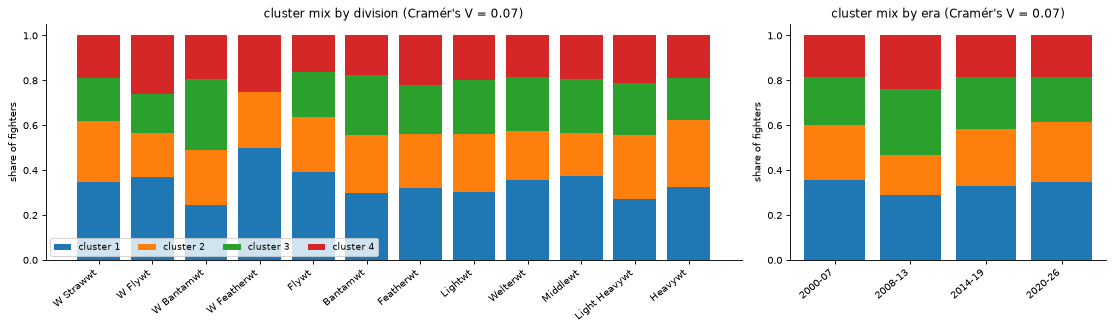

Cluster mix by division, row % (Cramér's V = 0.07):


cluster,fighters,1,2,3,4
division,,,,,
Women's Strawweight,63,35%,27%,19%,19%
Women's Flyweight,46,37%,20%,17%,26%
Women's Bantamweight,41,24%,24%,32%,20%
Women's Featherweight,4,50%,25%,0%,25%
Flyweight,74,39%,24%,20%,16%
Bantamweight,120,30%,26%,27%,18%
Featherweight,128,32%,24%,22%,22%
Lightweight,206,30%,26%,24%,20%
Welterweight,186,35%,22%,24%,18%


Cluster mix by era, row % (Cramér's V = 0.07):

cluster,fighters,1,2,3,4
event_date,,,,,
2000-07,70,36%,24%,21%,19%
2008-13,240,29%,18%,30%,24%
2014-19,415,33%,25%,23%,19%
2020-26,515,35%,27%,20%,18%
all fighters,1240,33%,24%,23%,20%


In [12]:
conf4 = show_confound(CL.RUNNER_UP_K)

## 7. Saved outputs

`python src/clustering.py` writes:

- `data/processed/cluster_probabilities.csv`: each eligible fighter's k = 3 membership probabilities, hard cluster, max probability and PC scores
- `data/processed/models/style_model_k3.joblib` and `style_model_k4.joblib`: the fitted PCA and Gaussian mixture, with cluster order and fit metadata

Load a model with `clustering.StyleModel.load(path)` and apply it to `features.build_profiles(as_of=...)` with `.assign(profiles)`.
See `docs/clustering.md` for the leakage caveats of doing that.

In [13]:
saved = CL.StyleModel.load(CL.MODEL_DIR / f"style_model_k{CL.CHOSEN_K}.joblib")
check = saved.assign(profiles).set_index("fighter_id").loc[X.index]
print("saved model reproduces this notebook's k = 3 probabilities:",
      np.allclose(check.filter(like="p_cluster").values, assign[CL.CHOSEN_K].filter(like="p_cluster").values))
print(saved.metadata)

saved model reproduces this notebook's k = 3 probabilities: True
{'fitted_at_utc': '2026-11-21T00:47:53+00:00', 'profiles_as_of': None, 'n_fighters': 1240, 'k': 3, 'n_components': 5, 'explained_variance': [0.3659, 0.183, 0.1138, 0.1065, 0.0761], 'prior_minutes': 60.0, 'feature_priors': {'sub_att_per15': 240.0}, 'min_fights': 5, 'start_date': '2000-01-01', 'seed': 0, 'n_init': 10}
